# HS4002 Week 1 Demo

## Basics of Python

We're working within the **pandas** + **plotnine** framework.

We'll explore a toy dataset about *Love Is Blind* contestants to answer: **to what extent does age, gender, and race affect the likelihood of marriage in LIB?**

In [43]:
import pandas as pd # import the packages we need
import numpy as np
import plotnine as p9
import warnings
warnings.filterwarnings('ignore')

## Loading the Dataset

In [44]:
file_location = "lib_toy.csv"
df = pd.read_csv(file_location)

# What does a dataset usually look like?

In [45]:
df.head() # give first 5 rows of df

,Name,Season,Partner,Age,Married,Race,Gender,Unnamed: 7
0,Lauren Speed,1,Cameron Hamilton,32,1,Black,1,LIB + Lauren Speed
1,Cameron Hamilton,1,Lauren Speed,28,1,White,0,LIB + Cameron Hamilton
2,Amber Pike,1,Matthew Barnett,27,1,White,1,LIB + Amber Pike
3,Matthew Barnett,1,Amber Pike,27,1,White,0,LIB + Matthew Barnett
4,Giannina Gibelli,1,Damian Powers,25,0,Hispanic,1,LIB + Giannina Gibelli


# Univariate Analysis

In [46]:
df.describe() # generate descriptive statistics for variables

,Season,Age,Married,Gender
count,120.000000,120.000000,120.000000,120.000000
mean,5.650000,30.708333,0.266667,0.500000
std,2.972281,3.090772,0.444071,0.502096
min,1.000000,24.000000,0.000000,0.000000
25%,3.000000,28.000000,0.000000,0.000000
50%,6.000000,31.000000,0.000000,0.500000
75%,8.000000,33.000000,1.000000,1.000000
max,10.000000,39.000000,1.000000,1.000000


In [47]:
df['Race'].value_counts() # count the number of people for each race

Race
White       67
Black       33
Hispanic    12
Asian        6
Mixed        2
Name: count, dtype: int64

## How many seasons of LIB are in this dataset?

In [48]:
df['Season'].value_counts()

Season
10    16
4     14
7     14
1     12
2     12
9     12
3     10
5     10
6     10
8     10
Name: count, dtype: int64

## How many contestants got married?

In [49]:
df['Married'].value_counts()

Married
0    88
1    32
Name: count, dtype: int64

## Univariate Plots

Let's make a histogram of the age distribution using `plotnine` — the grammar is identical to ggplot2. Note that column names in `aes()` are quoted strings in Python.

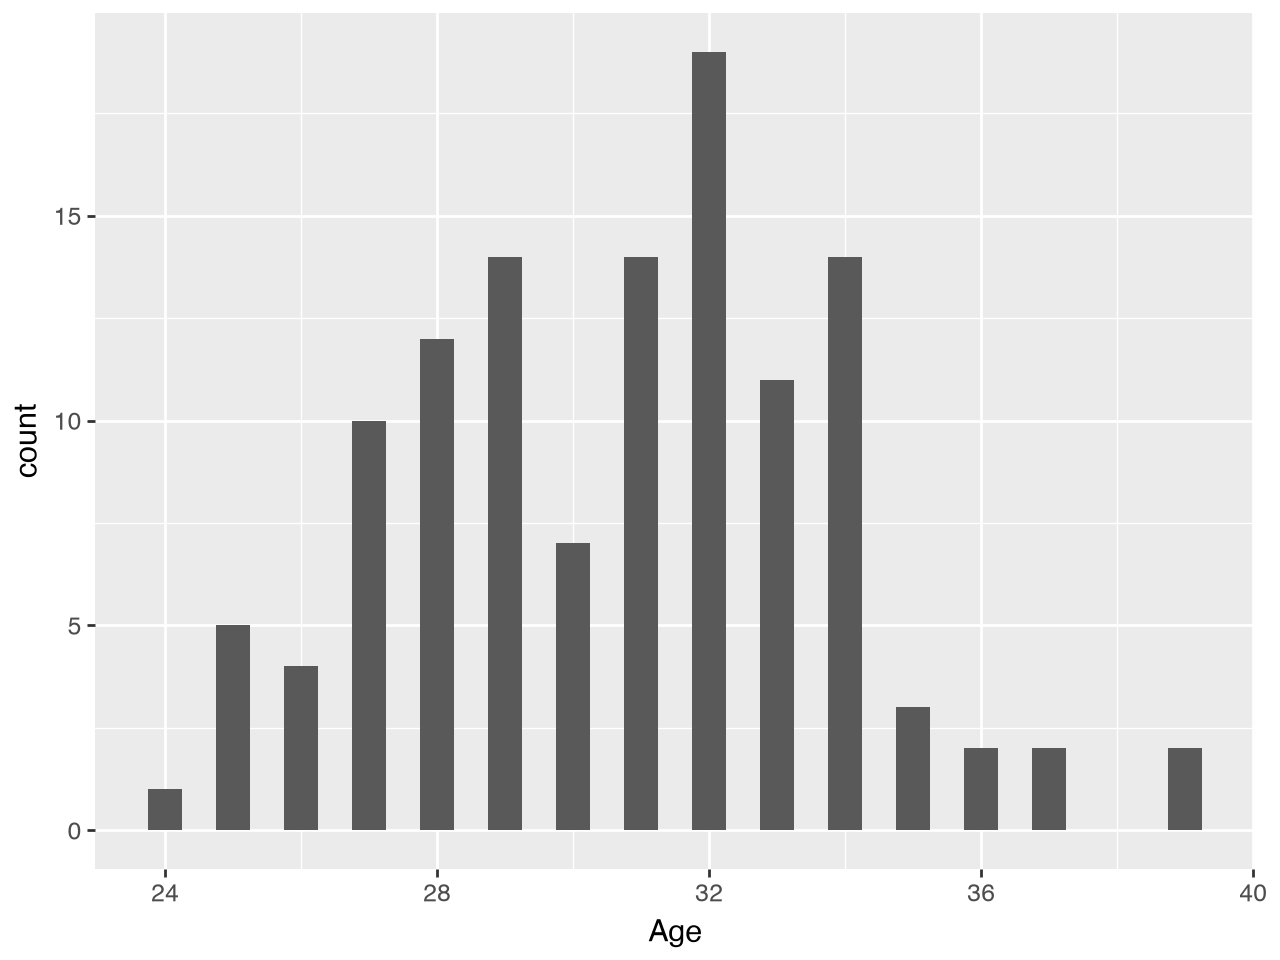

In [50]:
(
    p9.ggplot(df) + # plot a graph using df
    p9.geom_histogram(p9.aes(x='Age'), binwidth=0.5) # plot a histogram of the age of contestants
)

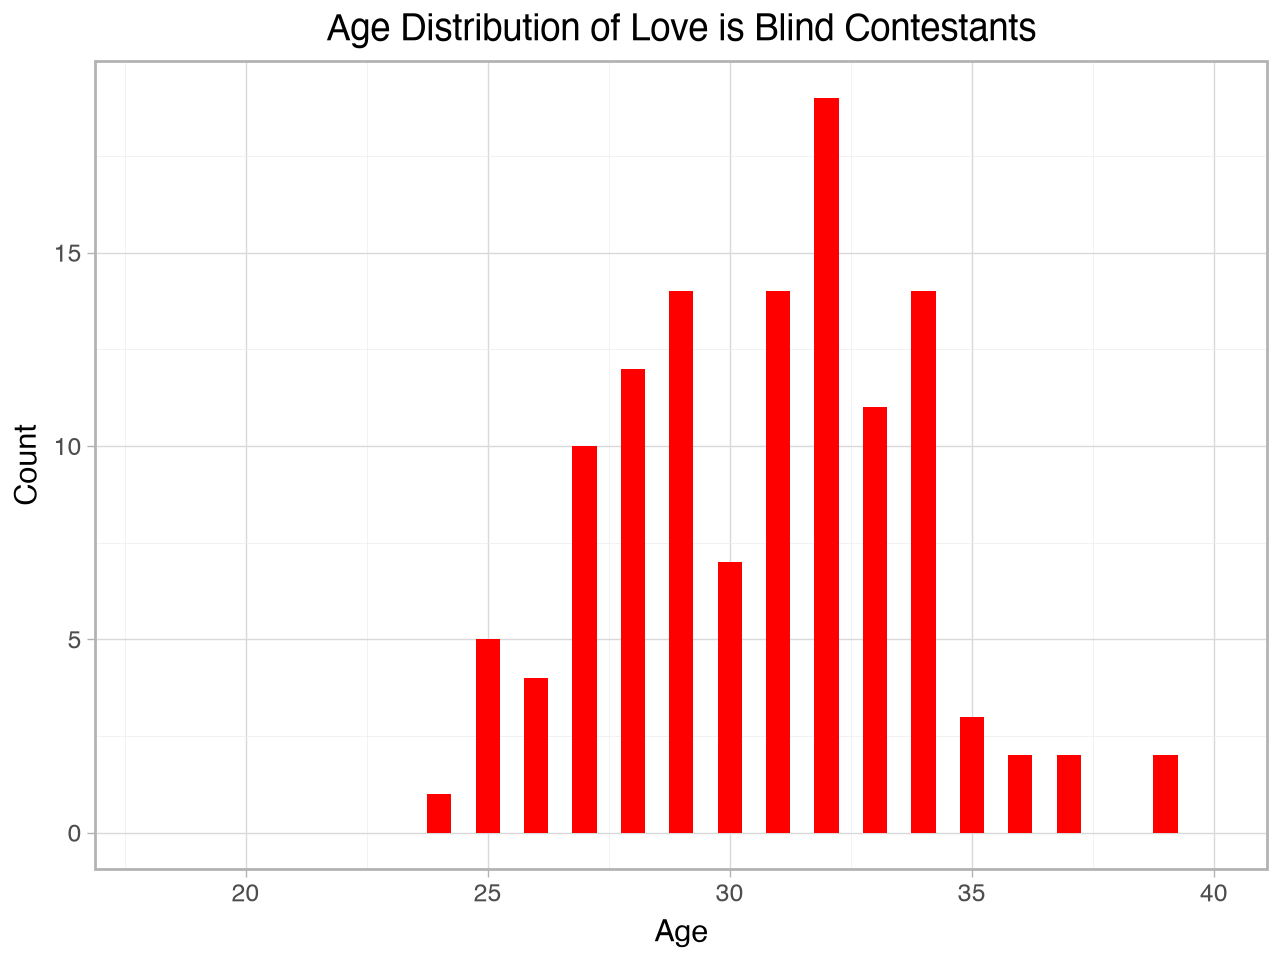

In [51]:
fig_fn = "ntu4eva.png"

p = (
    p9.ggplot(df) +
    p9.geom_histogram(p9.aes(x="Age"), binwidth=0.5, fill="red") +
    p9.theme_light() +
    p9.xlim(18, 40) + # set the limits for x-axis
    p9.labs(y="Count", x="Age", title="Age Distribution of Love is Blind Contestants")
)
p.save(fig_fn, width=30, height=17, units="cm") # save this graph as an image file!
p

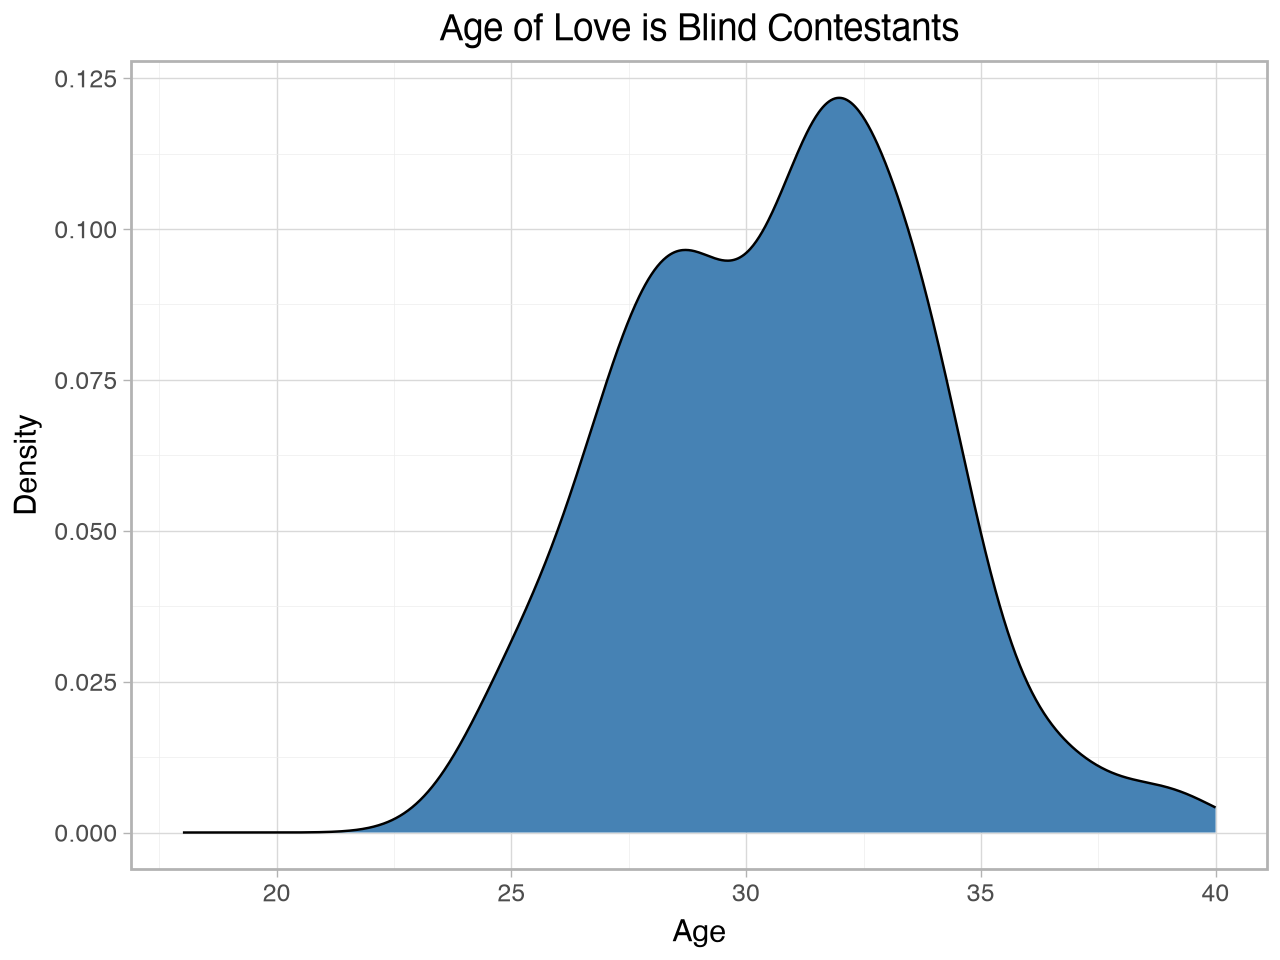

In [52]:
fig_fn = "ntu4eva.png"

p = (
    p9.ggplot(df) +
    p9.geom_density(p9.aes(x="Age"), fill="steelblue") + # plot a density cruve of age of contestants
    p9.theme_light() +
    p9.xlim(18, 40) +
    p9.labs(y="Density", x="Age", title="Age of Love is Blind Contestants")
)
p.save(fig_fn, width=30, height=17, units="cm")
p

# Does Age Matter?

How does age relate to the likelihood of a contestant getting married?

In [53]:
df.groupby('Married')['Age'].mean() # groups people by whether they are married or not, then calculates the average age of each group

Married
0    30.636364
1    30.906250
Name: Age, dtype: float64

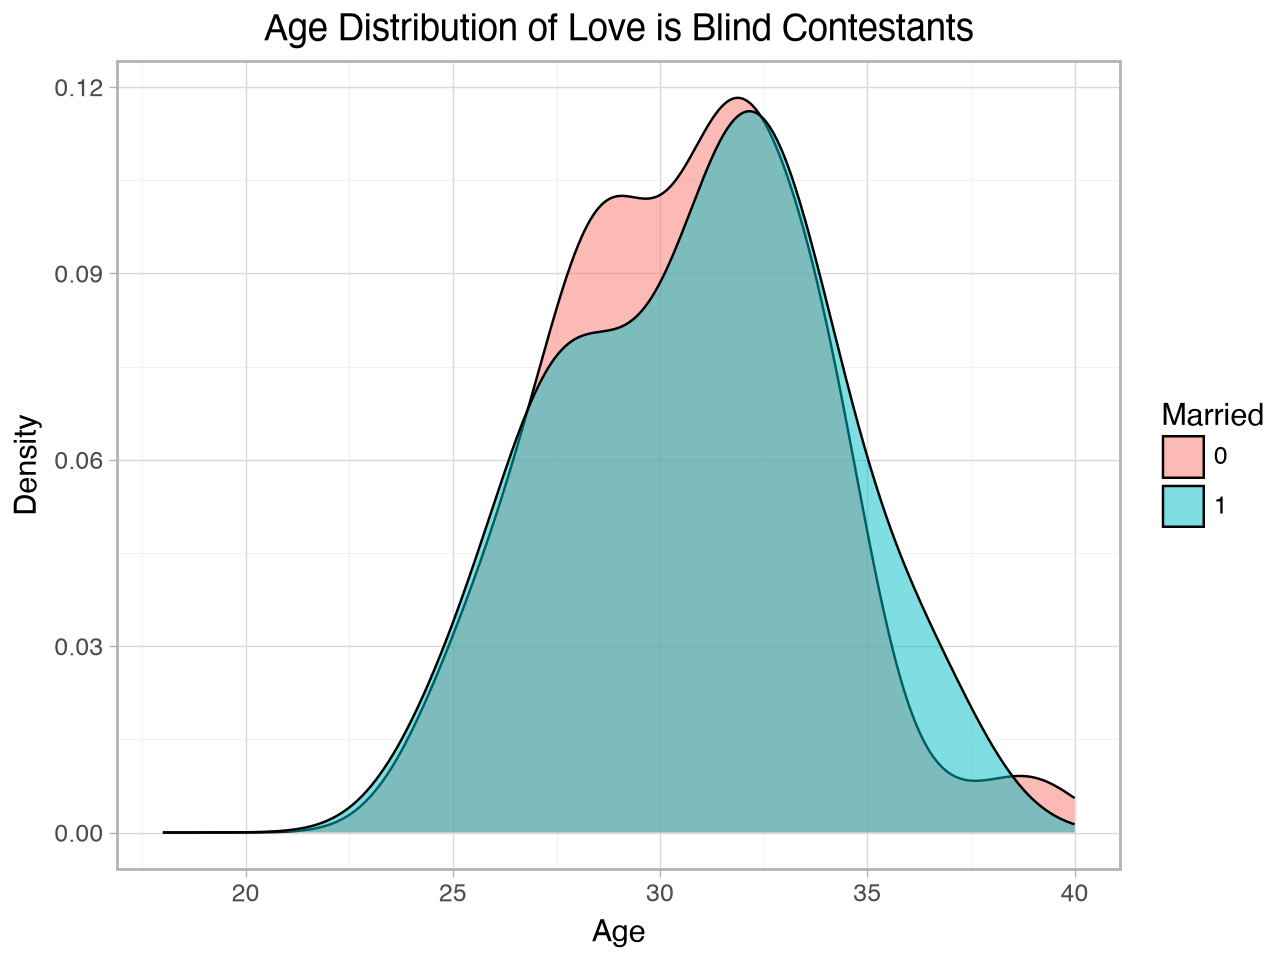

In [54]:
fig_fn = "age_by_maritalstatus.png"

p = (
    p9.ggplot(df) +
    p9.geom_density(p9.aes(x="Age", fill="factor(Married)"), position="identity", alpha=0.5) + # postition = identity tells python to put the graphs on top of each other, thus allowing overlapping 
    p9.theme_light() +
    p9.xlim(18, 40) +
    p9.labs(y="Density", x="Age",
         title="Age Distribution of Love is Blind Contestants",
         fill="Married") # name of the legend
)
p.save(fig_fn, width=30, height=17, units="cm")
p

# Let's Throw Race Into the Mix

In [55]:
df.groupby(['Married', 'Race'])['Age'].mean()

Married  Race    
0        Asian       30.500000
         Black       30.700000
         Hispanic    29.700000
         White       30.807692
1        Black       32.076923
         Hispanic    30.000000
         Mixed       31.500000
         White       29.933333
Name: Age, dtype: float64

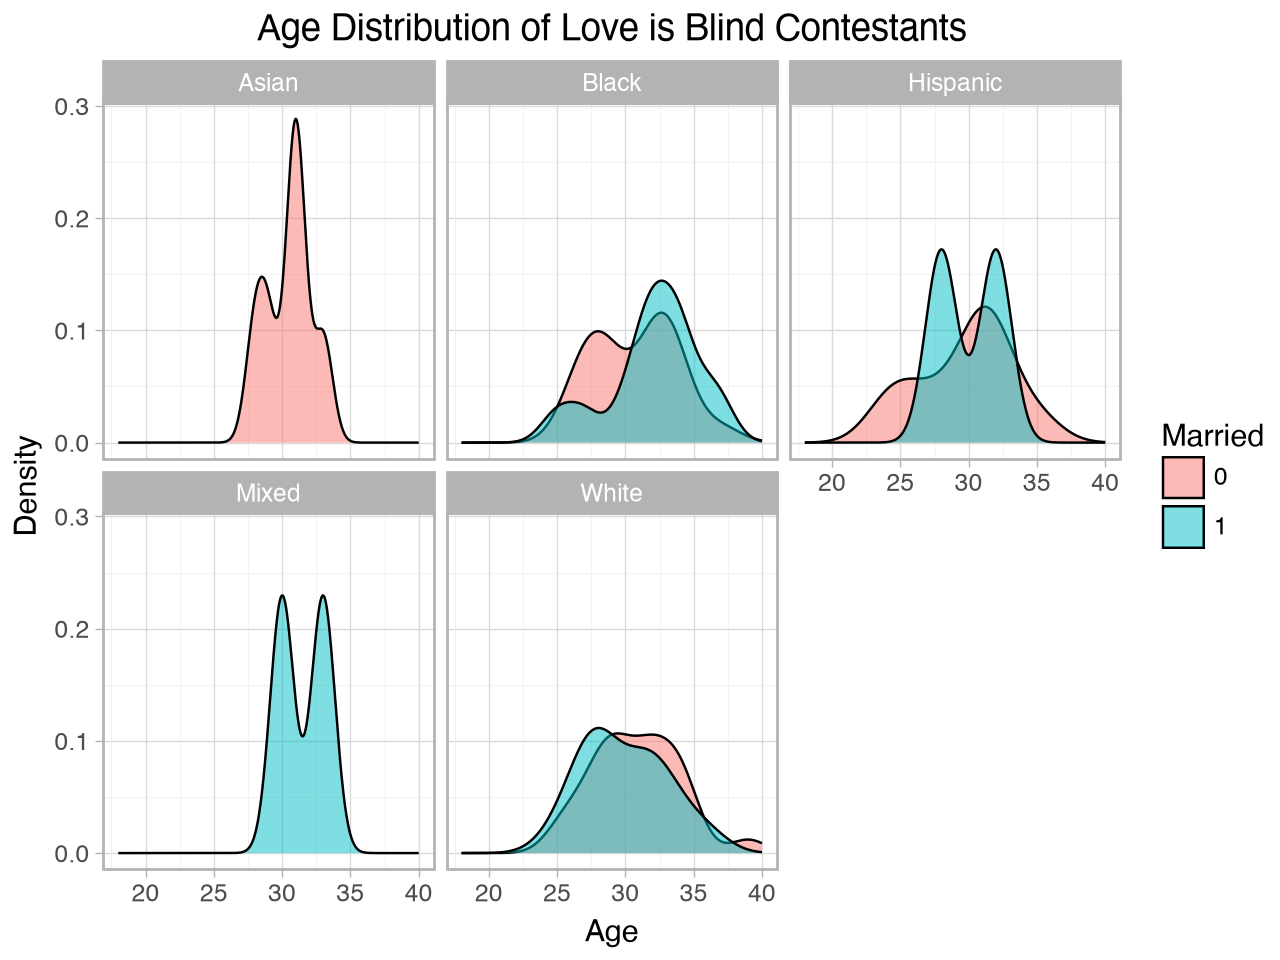

In [56]:
fig_fn = "age_marital_race.png"

p = (
    p9.ggplot(df) +
    p9.geom_density(p9.aes(x="Age", fill="factor(Married)"), position="identity", alpha=0.5) +
    p9.facet_wrap("Race") + # make a separate graph for each race!
    p9.theme_light() +
    p9.xlim(18, 40) +
    p9.labs(y="Density", x="Age",
         title="Age Distribution of Love is Blind Contestants",
         fill="Married")
)
p.save(fig_fn, width=30, height=17, units="cm")
p

# Trying Adding Gender!

In [57]:
df = df.assign(Gender=np.where(df['Gender'] == 1, 'Woman', 'Man'))
# rewrite the gender column. if it is 1, write as women, if not, write as man

df.groupby(['Married', 'Gender'])['Age'].mean()

Married  Gender
0        Man       30.204545
         Woman     31.068182
1        Man       31.250000
         Woman     30.562500
Name: Age, dtype: float64

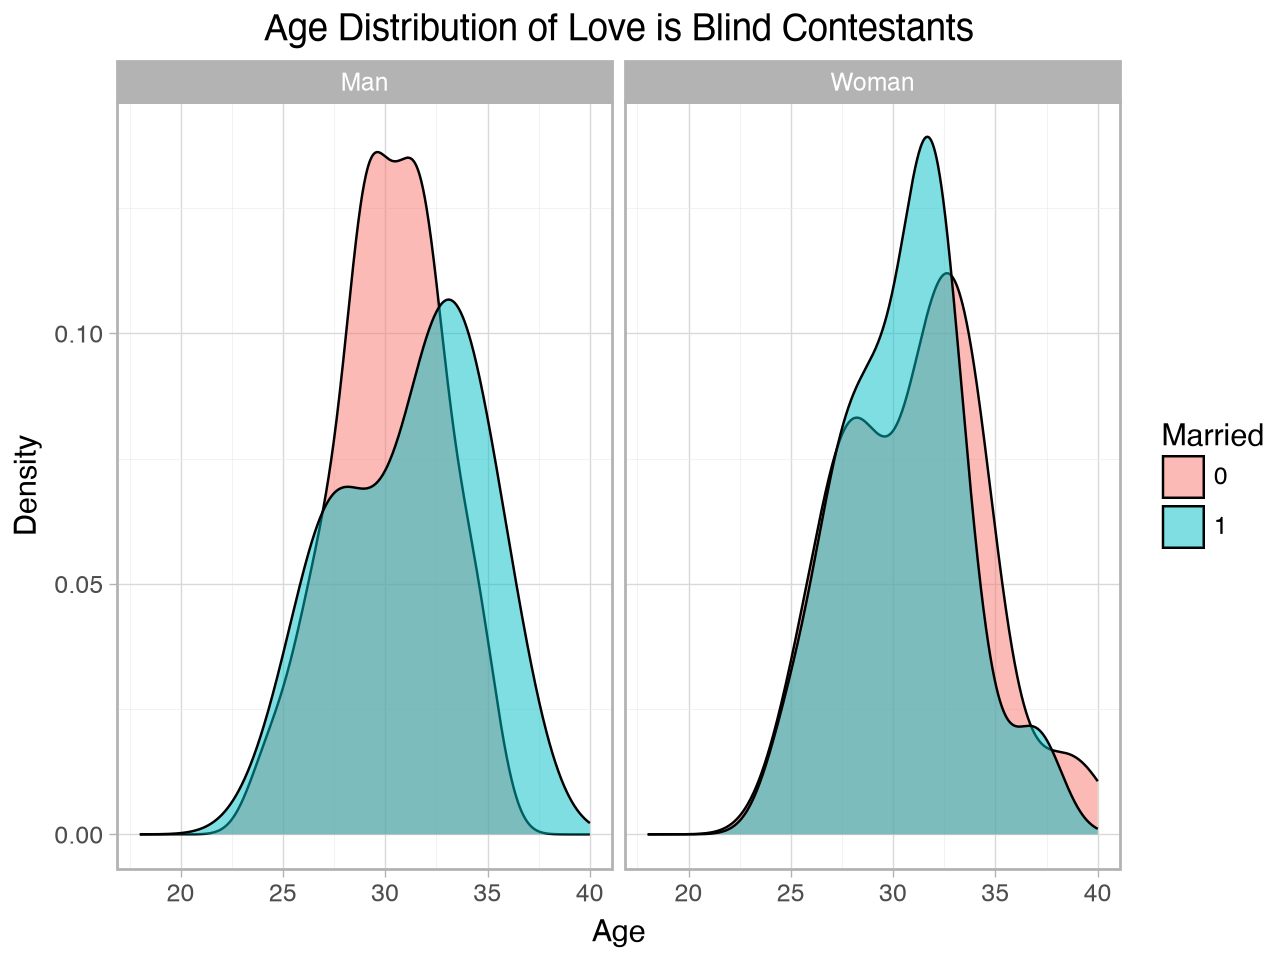

In [58]:
fig_fn = "age_marital_gender.png"

p = (
    p9.ggplot(df) +
    p9.geom_density(p9.aes(x="Age", fill="factor(Married)"), position="identity", alpha=0.5) +
    p9.facet_wrap("Gender") +
    p9.theme_light() +
    p9.xlim(18, 40) +
    p9.labs(y="Density", x="Age",
         title="Age Distribution of Love is Blind Contestants",
         fill="Married")
)
p.save(fig_fn, width=30, height=17, units="cm")
p

In [59]:
!jupyter nbconvert --to pdf week1_notebook.ipynb

[NbConvertApp] Converting notebook week1_notebook.ipynb to pdf
[NbConvertApp] Support files will be in week1_notebook_files/
[NbConvertApp] Making directory ./week1_notebook_files
[NbConvertApp] Writing 42513 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | bibtex had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 443257 bytes to week1_notebook.pdf
